# Import

In [3]:

from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

# Librerie
import pandas as pd
import numpy as np

# High Dimensionality
from pyod.models.abod import ABOD

# Ensemble
from pyod.models.feature_bagging import FeatureBagging
# carico LOF per FeaBag, chiaramente si può cambiare a seconda del modello semplice scelto
from pyod.models.lof import LOF
from pyod.models.loda import LODA

# Foreste
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

from sklearn.manifold import TSNE


# Data Preparation

In [2]:
df = pd.read_csv("a_cmi_internet.csv")
#legenda = pd.read_csv("data_dictionary.csv")

# Stagioni enceoded winter=0, spring=1, summer=2, autumn=3
df_da_imp= df.copy()

In [3]:
# Colonne just to check
col_categoriche = df_da_imp.select_dtypes(include=["object"]).columns
col_numeriche = df_da_imp.select_dtypes(
    include=["int64", "float64"]).columns
col_quantitative = df_da_imp.select_dtypes(
    include=["int64", "float64"]).columns.drop("id")

col_da_escludere = [
    "FGC-FGC_CU_Zone", "FGC-FGC_GSND_Zone", "FGC-FGC_GSD_Zone",
    "FGC-FGC_PU_Zone", "FGC-FGC_SRL_Zone", "FGC-FGC_SRR_Zone",
    "FGC-FGC_TL_Zone"
]

col_non_bin = col_quantitative.difference(col_da_escludere)

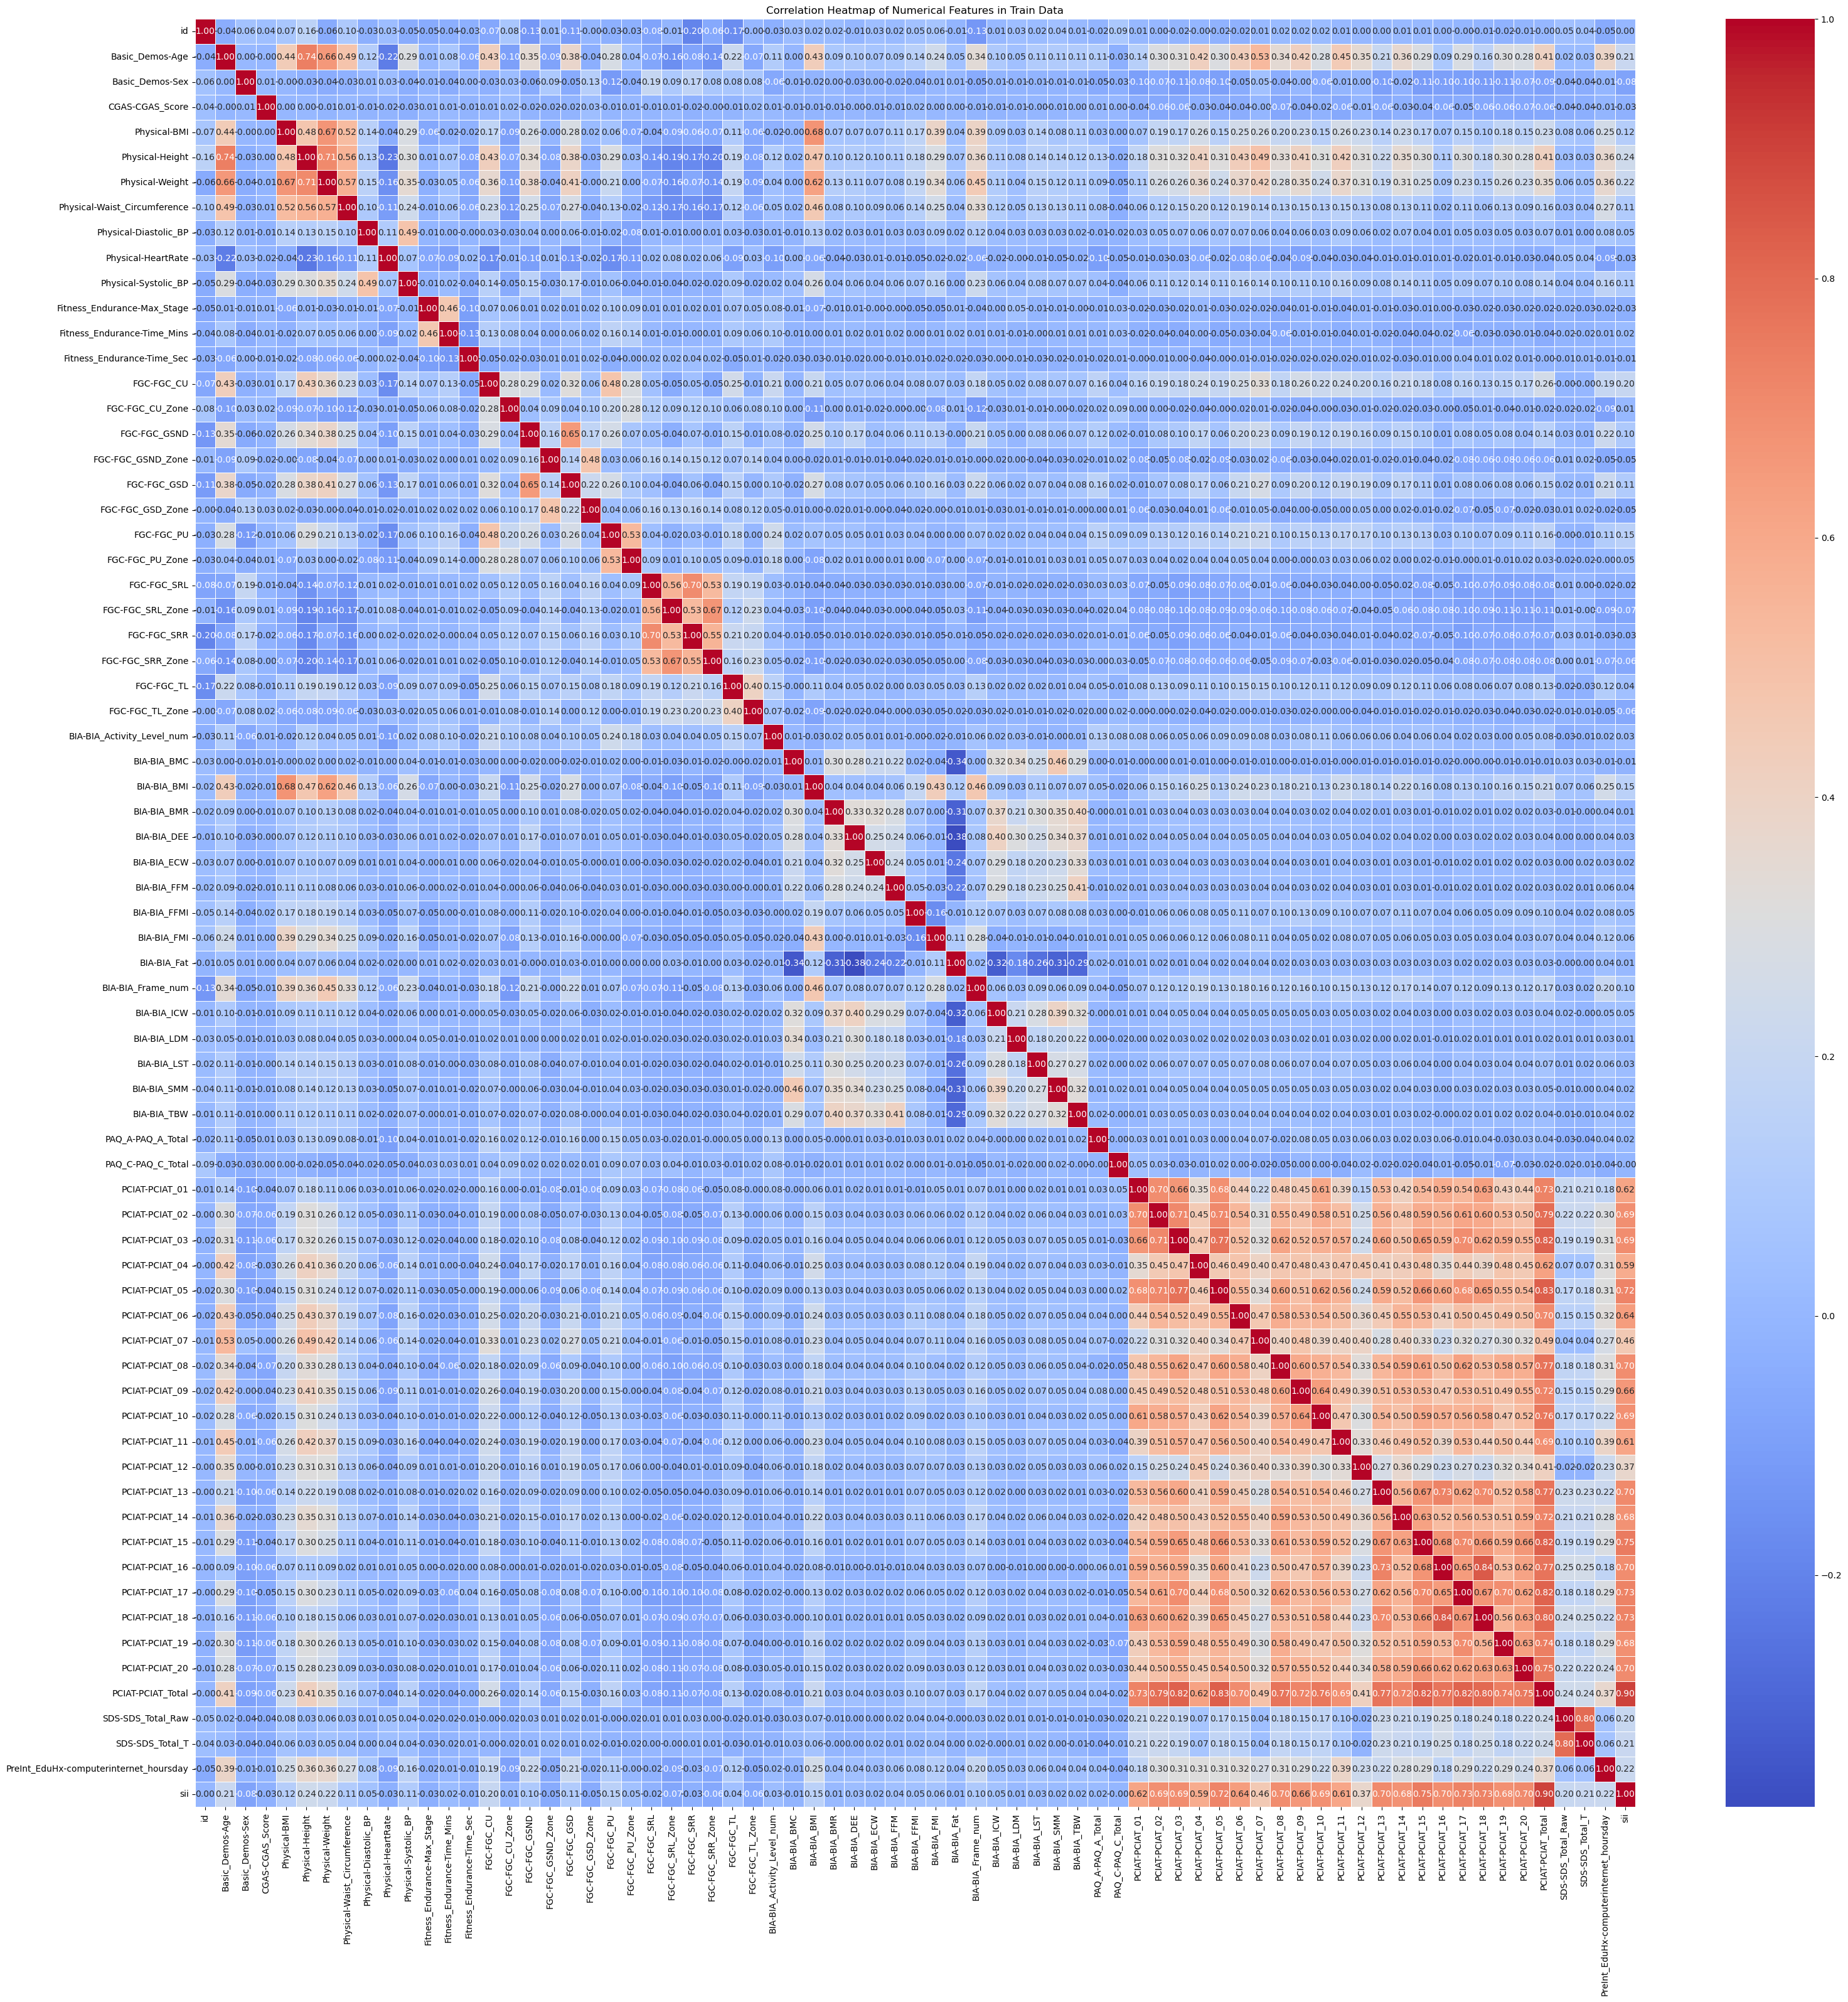

In [4]:
# Select only numerical columns for correlation matrix
numerical_columns = df.select_dtypes(include=['float64', 'int64'])

# Compute the correlation matrix
corr = numerical_columns.corr()

# Heatmap of correlation matrix
plt.figure(figsize=(32, 32))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features in Train Data')
plt.tight_layout()
#plt.show()

In [5]:
# Rimuovere 18+
# 0 = nan da lista
# paq Da arrotondare

# CGAS-CGAS_Score fuori scala

df_da_imp["CGAS-CGAS_Score"] = df_da_imp["CGAS-CGAS_Score"].mask(lambda x: x > 100, np.nan)

df_da_imp = df_da_imp[df_da_imp["Basic_Demos-Age"] <= 18]

colonne_zeri = ['Physical-Weight', 'Physical-Diastolic_BP', 'Physical-Systolic_BP']
df_da_imp[colonne_zeri] = df_da_imp[colonne_zeri].mask(lambda x: x == 0, np.nan)

'''
- le stagioni sono da lasciare. una volta imputate si arrotondano i valori che escono per il BMI. 
- i valori delle due colonne bmi sono diversi quindi lo ricalcoliamo noi dopo aver imputato altezza e peso
- da togliere Fitness_Endurance-Time_Mins e Fitness_Endurance-Time_Sec visto 
    che abbiamo crea to Fitness_Endurance-Tempo_totale che le include entrambe
- tutte le paq sono da rimuovere: troppi valori mancanti inoltre non ha senso visto che alcune righe sono considerate sia come 
    adolescenti che come bambini. anche ridondante visto che abbiamo già abbastanza valori sull'attività fisica.
    sono pure fuori scala'''

df_da_imp['Fitness_Endurance-Tempo_totale'] = df_da_imp['Fitness_Endurance-Time_Sec'] + \
    (df_da_imp['Fitness_Endurance-Time_Mins']*60)

df_da_imp= df_da_imp.drop(['Fitness_Endurance-Time_Mins','Fitness_Endurance-Time_Sec'], axis=1)

df_da_imp= df_da_imp.drop(['PAQ_A-Season','PAQ_A-PAQ_A_Total','PAQ_C-Season','PAQ_C-PAQ_C_Total'], axis=1)

df_da_imp= df_da_imp.drop(['Physical-BMI','BIA-BIA_BMI'], axis=1)

In [6]:
variabili_cat = ['Basic_Demos-Enroll_Season','Basic_Demos-Sex','CGAS-Season',
'Physical-Season','Fitness_Endurance-Season','FGC-Season',
"FGC-FGC_CU_Zone", "FGC-FGC_GSND_Zone", "FGC-FGC_GSD_Zone",
"FGC-FGC_PU_Zone", "FGC-FGC_SRL_Zone", "FGC-FGC_SRR_Zone",
"FGC-FGC_TL_Zone",'BIA-Season','BIA-BIA_Activity_Level_num','BIA-BIA_Frame_num',
'PCIAT-Season', 'PCIAT-PCIAT_01', 'PCIAT-PCIAT_02', 'PCIAT-PCIAT_03',
'PCIAT-PCIAT_04', 'PCIAT-PCIAT_05', 'PCIAT-PCIAT_06', 'PCIAT-PCIAT_07',
'PCIAT-PCIAT_08', 'PCIAT-PCIAT_09', 'PCIAT-PCIAT_10', 'PCIAT-PCIAT_11',
'PCIAT-PCIAT_12', 'PCIAT-PCIAT_13', 'PCIAT-PCIAT_14', 'PCIAT-PCIAT_15',
'PCIAT-PCIAT_16', 'PCIAT-PCIAT_17', 'PCIAT-PCIAT_18', 'PCIAT-PCIAT_19',
'PCIAT-PCIAT_20','SDS-Season','PreInt_EduHx-Season',
'PreInt_EduHx-computerinternet_hoursday']

In [7]:
stagioni = {"Winter": 0, "Spring": 1, "Summer": 2, "Fall": 3}
df_lavoro = df_da_imp.replace(stagioni)

X_features = df_lavoro.drop(['id', 'sii'], axis=1)
y_target = df_lavoro['sii'].astype(int)
df_id = df_lavoro['id']

X_train, X_test, y_train, y_test = train_test_split(
    X_features, y_target, test_size=0.3, random_state=0, stratify=y_target
)

rf_estimator = RandomForestRegressor(n_estimators=20, random_state=222, n_jobs=-1)
imputer_rf = IterativeImputer(estimator=rf_estimator, random_state=222, max_iter=5)

X_train_imp_array = imputer_rf.fit_transform(X_train)
X_test_imp_array = imputer_rf.transform(X_test)

X_train_imp = pd.DataFrame(X_train_imp_array, columns=X_train.columns, index=X_train.index)
X_test_imp = pd.DataFrame(X_test_imp_array, columns=X_test.columns, index=X_test.index)

train_completo = X_train_imp.assign(sii=y_train)
test_completo = X_test_imp.assign(sii=y_test)

df_final_features = pd.concat([train_completo, test_completo]).sort_index()

df_final_features.insert(0, 'id', df_id)
df_imp_et = df_final_features  

/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_25894/393553868.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_lavoro = df_da_imp.replace(stagioni)
/opt/anaconda3/lib/python3.13/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [8]:
df_imp_et[variabili_cat]= df_imp_et[variabili_cat].round() 
df_imp_et["bmi"] = (df_imp_et["Physical-Weight"] / (df_imp_et["Physical-Height"] ** 2)) * 703


In [9]:
# Salvataggio dati in parquet
df_imp_et.to_parquet('df_imp_et.parquet')

# Outliers Detection

In [66]:
df_imp_et= pd.read_parquet('df_imp_et.parquet')
standard_scaler = StandardScaler().set_output(transform="pandas")
minmax_scaler = MinMaxScaler()

droppare_per_X= ['sii', 'id']

y=np.array(df_imp_et['sii'])
X = df_imp_et.drop(droppare_per_X, axis=1)
X_standard = pd.DataFrame(
    standard_scaler.fit_transform(X), 
    columns=X.columns, 
    index=X.index
)
y = y.astype(int)

X_train, X_test, _, _ = train_test_split(X_standard, y, test_size=0.3, random_state=0)

In [67]:
X_standard.to_parquet('X_standard.parquet')

In [68]:
# Ensemble: FeaBag

feabag_model = FeatureBagging(
    base_estimator=LOF(),  # stimatore base, si può cambiare
    n_estimators=100,  # da testare coi dati veri per capire quanto ci vuole
    max_features=0.5,  # proporzione di variabili da estrarre per ogni modello
    contamination=0.01,  # come prima, 1% di outliers
    random_state=222,
    n_jobs=-1 
)
feabag_model.fit(X_standard)

feabag_preds = feabag_model.predict(X_standard)

In [69]:
#Foreste: Extended Forest

# In isotree, ndim=1 equivale a Isolation Forest standard.
# Scegliere ndim=df.shape[1] per la Extended Isolation Forest completa.
extended_forest_model = EIF(
    sample_size=256,  # come prima
    ntrees=100,  # numero alberi
    # serve a dire al modello che vogliamo la versione estesa
    ndim=X_standard.shape[1],
    random_seed=222,
    n_jobs=-1
)
extended_forest_model.fit(X_standard)

# EIF genera uno score (più alto = più probabile outlier)
extended_forest_scores = extended_forest_model.predict(X_standard)

# gli outlier vanno trovati a mano
threshold = np.percentile(extended_forest_scores, 99)  # 99 percentile
extended_forest_preds = (extended_forest_scores > threshold).astype(int)

91


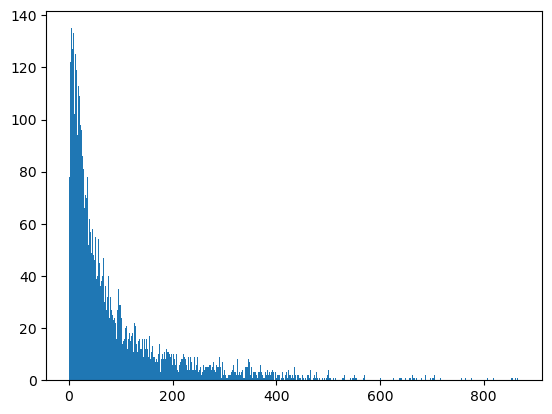

Numero di outlier trovati: 162 (1.95%)


In [70]:
import math as m
#Distanza: RKNN
# 1. Trova i k-vicini per ogni punto
k = int(m.sqrt(len(X_standard)))
nbrs = NearestNeighbors(n_neighbors=k).fit(X_standard)
distances, indices = nbrs.kneighbors(X_standard)
print(k)
# 2. Conta quante volte ogni indice compare nella matrice dei vicini
# 'indices' contiene gli indici dei k vicini per ogni riga
flat_indices = indices.flatten()
counts = np.bincount(flat_indices, minlength=len(X_standard))

# 3. Lo score RkNN è il conteggio (invertito)
# Più il conteggio è basso, più il punto è un outlier
rknn_scores = counts

out= np.percentile(rknn_scores, q=1)

outliers_rknn = np.zeros(len(rknn_scores))
outliers_rknn[rknn_scores <= out] = 1

plt.hist(rknn_scores, bins=range(int(np.max(rknn_scores))))
#plt.axvline(np.max(rknn_scores[np.where(out==1)]), c='k', linestyle='--')
plt.show()

n_outliers_rknn = np.sum(outliers_rknn)
print(f"Numero di outlier trovati: {int(n_outliers_rknn)} ({n_outliers_rknn/len(df_imp_et)*100:.2f}%)")



In [71]:
#Deviation-based Approaches: EllEnv

from sklearn.covariance import EllipticEnvelope

ellenv = EllipticEnvelope(random_state=222, contamination=0.01)
ellenv.fit(X_standard)

# predict returns 1 for an inlier and -1 for an outlier
outliers_ellenv = ellenv.predict(X_standard)

#print (outliers_ellenv)
np.unique(outliers_ellenv, return_counts=True)

n_outliers_ellenv = np.sum(outliers_ellenv == -1)
print(f"Numero di outlier trovati: {int(n_outliers_ellenv)} ({n_outliers_ellenv/len(df_imp_et)*100:.2f}%)")

Numero di outlier trovati: 84 (1.01%)


In [72]:

# High Dimensionality: Fast ABOD

#!!! LENTO, su portatile in carica ci mette 5+ minuti; sul fisso un paio

# Contamination è la proporzione di outliers; n_neighbors autoesplicativo
abod_model = ABOD(contamination=0.01, n_neighbors=k, n_jobs=-1)
abod_model.fit(X_standard)

# 0 = inliers e 1 = outliers
abod_preds = abod_model.predict(X_standard)
abod_scores = abod_model.decision_scores_


In [73]:
df_outliers = pd.DataFrame(
    np.column_stack((outliers_rknn, outliers_ellenv,
                    feabag_preds, extended_forest_preds,abod_preds)),
    columns=['rknn', 'ellenv', 'feabag', 'ext_forest', 'abod']
)

df_outliers['risultati'] = (
    (df_outliers['rknn'] == 1).astype(int) +
    (df_outliers['ellenv'] == -1).astype(int) +
    (df_outliers['feabag'] == 1).astype(int) +
    (df_outliers['ext_forest'] == 1).astype(int) +
    (df_outliers['abod']== 1).astype(int)
)

df_outliers_2= df_outliers[df_outliers['risultati']>=2]
df_outliers_1= df_outliers[df_outliers['risultati']>=1]
df_outliers["colore"] = np.where(df_outliers["risultati"] >= 2, 1, 0)


In [74]:
# rimossi gli outliers che erano outliers per più di due metodi
df_risultati= df_imp_et.copy()
df_risultati['risultati'] = df_outliers['risultati'].values
df_pulito = df_risultati[df_risultati['risultati'] <= 1].copy()

print(f"Righe originali: {len(df_risultati)}")
print(f"Righe dopo il filtro: {len(df_pulito)}")

df_solo_out=df_risultati[df_risultati['risultati'] > 1].copy()

Righe originali: 8319
Righe dopo il filtro: 8231


In [75]:
df_outliers.to_parquet('df_outliers.parquet')
df_pulito.to_parquet('df_pulito.parquet')

# Dimensionality Reduction


In [43]:
X_standard= pd.read_parquet('X_standard.parquet')
df_outliers= pd.read_parquet('df_outliers.parquet')

In [44]:
%%time
#PCA
pca = PCA(n_components=3, random_state=222)
df_unito_pca = pca.fit_transform(X_standard)
print(pca.explained_variance_ratio_.sum()) 

0.2864518229633134
CPU times: user 3.48 ms, sys: 3.06 ms, total: 6.54 ms
Wall time: 5.55 ms


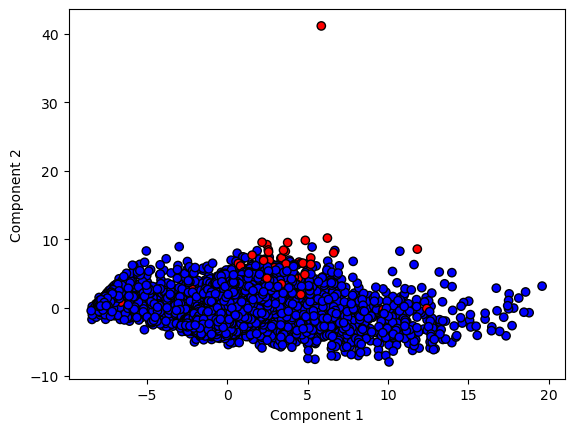

In [45]:
# 2D
fig, ax= plt.subplots()
plt.scatter(df_unito_pca[:, 0], df_unito_pca[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')

plt.show()

import plotly.express as px

# 1. Prepariamo il DataFrame
df_plot = pd.DataFrame({
    'Component 1': df_unito_pca[:, 0],
    'Component 2': df_unito_pca[:, 1],
    'Component 3': df_unito_pca[:, 2],
    'Colore': df_outliers['colore']
})

# 2. Creiamo lo scatter 3D con punti piccoli e nuovi colori
fig = px.scatter_3d(
    df_plot,
    x='Component 1',
    y='Component 2',
    z='Component 3',
    color='Colore',
    # --- MODIFICHE QUI ---
    color_continuous_scale='Viridis', # Cambia scala: 'Viridis', 'Plasma', 'Inferno', 'Turbo'
    opacity=0.7,                     # Leggera trasparenza aiuta a vedere la densità
)

# 3. Rimpicciolire i punti
# Plotly usa un default di circa 20. Impostando un valore fisso basso:
fig.update_traces(marker=dict(size=3)) # Prova valori tra 2 e 5

# 4. Opzionale: Titolo e layout
fig.update_layout(title="Analisi Outlier - Punti Rimpiccioliti")

fig.show()



In [46]:
%%time
import umap
#UMAP
umappe = umap.UMAP(n_components = 3, n_jobs=-1)
df_unito_umap = umappe.fit_transform(X_standard)

print(umappe)

UMAP(n_components=3, tqdm_kwds={'bar_format': '{desc}: {percentage:3.0f}%| {bar} {n_fmt}/{total_fmt} [{elapsed}]', 'desc': 'Epochs completed', 'disable': True})
CPU times: user 18.1 s, sys: 3.22 s, total: 21.3 s
Wall time: 2.22 s


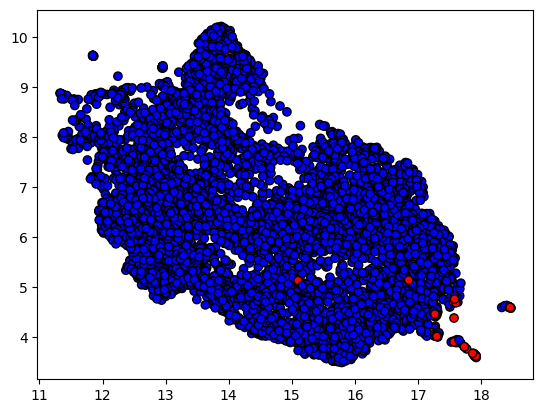

In [47]:
# 2D

plt.scatter(df_unito_umap[:, 0], df_unito_umap[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')

plt.show()
import plotly.express as px
import pandas as pd

# 1. Prepariamo il DataFrame
df_plot = pd.DataFrame({
    'Component 1': df_unito_umap[:, 0],
    'Component 2': df_unito_umap[:, 1],
    'Component 3': df_unito_umap[:, 2],
    'Colore': df_outliers['colore']
})

# 2. Creiamo lo scatter 3D con punti piccoli e nuovi colori
fig = px.scatter_3d(
    df_plot,
    x='Component 1',
    y='Component 2',
    z='Component 3',
    color='Colore',
    # --- MODIFICHE QUI ---
    color_continuous_scale='Plasma', # Cambia scala: 'Viridis', 'Plasma', 'Inferno', 'Turbo'
    opacity=0.7,                     # Leggera trasparenza aiuta a vedere la densità
)

# 3. Rimpicciolire i punti
# Plotly usa un default di circa 20. Impostando un valore fisso basso:
fig.update_traces(marker=dict(size=3)) # Prova valori tra 2 e 5

# 4. Opzionale: Titolo e layout
fig.update_layout(title="Analisi Outlier - Punti Rimpiccioliti")

fig.show()


In [79]:
tsne = TSNE(n_components=3, n_jobs=-1)
df_unito_tsne = tsne.fit_transform(X_standard)
X_standard.shape

(8319, 74)

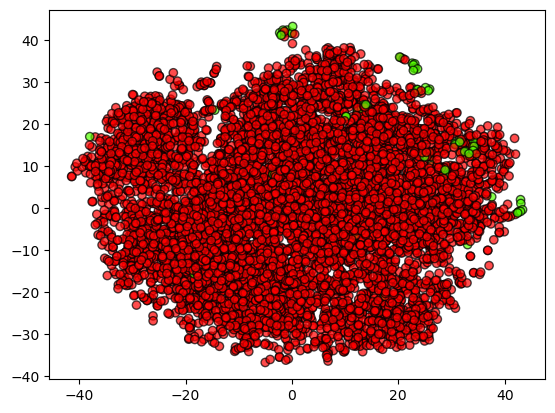

In [80]:
plt.scatter(df_unito_tsne[:, 0], df_unito_tsne[:, 1], c=df_outliers['colore'], cmap=plt.cm.prism, edgecolor='k', alpha=0.7)
plt.show()


# 1. Prepariamo il DataFrame
df_plot = pd.DataFrame({
    'Component 1': df_unito_tsne[:, 0],
    'Component 2': df_unito_tsne[:, 1],
    'Component 3': df_unito_tsne[:, 2],
    'Colore': df_outliers['colore']
})

# 2. Creiamo lo scatter 3D con punti piccoli e nuovi colori
fig = px.scatter_3d(
    df_plot,
    x='Component 1',
    y='Component 2',
    z='Component 3',
    color='Colore',
    # --- MODIFICHE QUI ---
    color_continuous_scale='Plasma', # Cambia scala: 'Viridis', 'Plasma', 'Inferno', 'Turbo'
    opacity=0.7,                     # Leggera trasparenza aiuta a vedere la densità
)

# 3. Rimpicciolire i punti
# Plotly usa un default di circa 20. Impostando un valore fisso basso:
fig.update_traces(marker=dict(size=3)) # Prova valori tra 2 e 5

# 4. Opzionale: Titolo e layout
fig.update_layout(title="Analisi Outlier - Punti Rimpiccioliti")

fig.show()


# Unbalanced Learning

In [1]:
import warnings
warnings.simplefilter("ignore")

In [4]:
df_pulito= pd.read_parquet('df_pulito.parquet')
df_unlearn=df_pulito.drop(['risultati'], axis=1).copy()

standard_scaler = StandardScaler().set_output(transform="pandas")

y_da_binarizzare= np.array(df_unlearn['sii'])
y_pulito = np.where(y_da_binarizzare == 3.0, 1, 0)

X_pulito = df_unlearn.drop(columns=['id','sii','PCIAT-PCIAT_Total']).copy()

X_pulito_s = pd.DataFrame(
    standard_scaler.fit_transform(X_pulito), 
    columns=X_pulito.columns, 
    index=X_pulito.index
)

X_trainp, X_testp, y_trainp, y_testp = train_test_split(X_pulito, y_pulito, test_size=0.3, random_state=100, stratify=y_pulito)
X_trainp_s, X_testp_s, y_trainp_s, y_testp_s = train_test_split(X_pulito_s, y_pulito, test_size=0.3, random_state=100, stratify=y_pulito)

#pd.Series(y_pulito).value_counts()
pd.Series(y_testp).value_counts()

0    2445
1      25
Name: count, dtype: int64

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_curve, auc, RocCurveDisplay


clf = DummyClassifier()
clf.fit(X_trainp, y_trainp)

y_pred0 = clf.predict(X_testp)

print('Accuracy %s' % accuracy_score(y_testp, y_pred0))
print('F1-score %s' % f1_score(y_testp, y_pred0, average=None))
print(classification_report(y_testp, y_pred0))

y_score = clf.predict_proba(X_testp)
#plot_roc(y_test, y_score)
plt.show()

# CONTROLLARE PER IPERPARAMETRI DI DECISIONTREE
clf = DecisionTreeClassifier(min_samples_leaf=3, random_state=222)
clf.fit(X_trainp, y_trainp)

y_pred0 = clf.predict(X_testp)

print('Accuracy %s' % accuracy_score(y_testp, y_pred0))
print('F1-score %s' % f1_score(y_testp, y_pred0, average=None))
print(classification_report(y_testp, y_pred0))

importances = pd.Series(clf.feature_importances_, index=X_trainp.columns)
print(importances.sort_values(ascending=False).head(5))

#PCIAT-PCIAT_Total            0.942548
#praticamente viene usata solo questa per fare gli split quindi va levata? suppongo

'''Ho rimosso la variabile #PCIAT-PCIAT_Total perché introduceva Target Leakage. Essendo il target una discretizzazione 
del punteggio totale, lasciarla avrebbe reso il problema banale, portando il modello a imparare una semplice regola aritmetica 
anziché i pattern comportamentali sottostanti. Rimuovendola, ho forzato il modello a lavorare sui singoli item, aumentando il valore 
diagnostico e la capacità di generalizzazione su nuovi soggetti di cui potremmo avere solo risposte parziali.

Senza il totale, il Decision Tree inizierà a pesare i singoli comportamenti. 
Scoprirai, ad esempio, che la domanda 20 ("Quanto spesso preferisci stare su internet invece di uscire con gli amici?")
pesa molto più della domanda 4.
Interpretabilità: Potrai dire: "Il modello ha individuato che non è il punteggio totale a contare, ma questi 4 comportamenti specifici 
che, se presenti contemporaneamente, portano alla classe 3".'''

Accuracy 0.9898785425101214
F1-score [0.99491353 0.        ]
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2445
           1       0.00      0.00      0.00        25

    accuracy                           0.99      2470
   macro avg       0.49      0.50      0.50      2470
weighted avg       0.98      0.99      0.98      2470

Accuracy 0.9902834008097166
F1-score [0.99511202 0.2       ]
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      2445
           1       0.60      0.12      0.20        25

    accuracy                           0.99      2470
   macro avg       0.80      0.56      0.60      2470
weighted avg       0.99      0.99      0.99      2470

PCIAT-PCIAT_08       0.196374
PCIAT-PCIAT_07       0.162305
PCIAT-PCIAT_20       0.084730
BIA-BIA_FFM          0.061625
SDS-SDS_Total_Raw    0.059302
dtype: float64


'Ho rimosso la variabile #PCIAT-PCIAT_Total perché introduceva Target Leakage. Essendo il target una discretizzazione \ndel punteggio totale, lasciarla avrebbe reso il problema banale, portando il modello a imparare una semplice regola aritmetica \nanziché i pattern comportamentali sottostanti. Rimuovendola, ho forzato il modello a lavorare sui singoli item, aumentando il valore \ndiagnostico e la capacità di generalizzazione su nuovi soggetti di cui potremmo avere solo risposte parziali.\n\nSenza il totale, il Decision Tree inizierà a pesare i singoli comportamenti. \nScoprirai, ad esempio, che la domanda 20 ("Quanto spesso preferisci stare su internet invece di uscire con gli amici?")\npesa molto più della domanda 4.\nInterpretabilità: Potrai dire: "Il modello ha individuato che non è il punteggio totale a contare, ma questi 4 comportamenti specifici \nche, se presenti contemporaneamente, portano alla classe 3".'

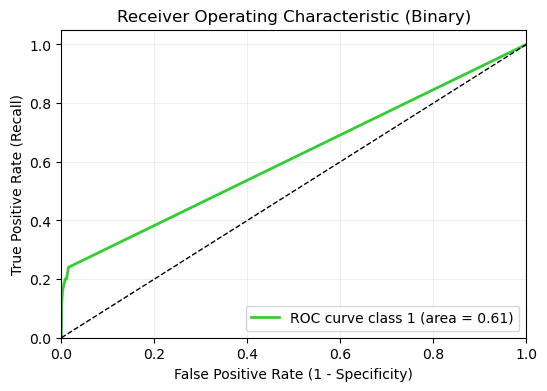

In [21]:
from sklearn.metrics import roc_curve, auc, RocCurveDisplay

y_score0 = clf.predict_proba(X_testp)[:, 1]
fpr0, tpr0, thresholds0 = roc_curve(y_testp, y_score0)
roc_auc0 = auc(fpr0, tpr0)

plt.figure(figsize=(6, 4))
plt.plot(fpr0, tpr0, color='limegreen', lw=2, 
         label=f'ROC curve class 1 (area = {roc_auc0:.2f})')

plt.plot([0, 1], [0, 1], color='black', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (Binary)')
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.show()

In [7]:
# storing class 1 ROC curve for successive comparisons
def plot_ROC_comparison(fpr, tpr):
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr0, tpr0, color='darkorange', lw=3, label='$AUC_0$ = %.3f' % (roc_auc0))
    plt.plot(fpr, tpr, color='green', lw=3, label='$AUC_1$ = %.3f' % (roc_auc))
    
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=16)
    plt.ylabel('True Positive Rate', fontsize=16)
    plt.title('ROC curve', fontsize=16)
    plt.legend(loc="lower right", fontsize=14, frameon=False)
    plt.tick_params(axis='both', which='major', labelsize=16)
    plt.show()

def plot_pca(X_pca, y_train):
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap=plt.cm.prism, edgecolor='k', alpha=0.7)
    plt.show()

In [8]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.under_sampling import CondensedNearestNeighbour
from imblearn.under_sampling import TomekLinks
from imblearn.under_sampling import EditedNearestNeighbours
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import ADASYN

## Scelte finali

1. Undersampling: CondensedNearestNeighbour
2. Oversampling: SMOTE o ADASYN
3. Balancing at the Algorithm Level: Class Weight

### Scelta Parametri: Condensed Nearest Neighbour (CNN)
**Logica della scelta:**
Il Condensed Nearest Neighbour è una tecnica di undersampling molto selettiva. I parametri principali da regolare sono `n_neighbors` (il numero di vicini da considerare per valutare se un punto è ridondante o meno) e `n_seeds_S` (il numero di campioni della classe maggioritaria con cui inizializzare il sottoinsieme). 
Considerando la dimensione ridotta della classe minoritaria (25 campioni), un `n_neighbors` elevato potrebbe portare alla rimozione di troppi campioni, degradando il confine decisionale. Pertanto, testeremo `n_neighbors` pari a 1 (di default, più fedele al confine) e 3 (per una maggiore robustezza al rumore).

--- Valutazione parametri per CNN ---

Test con n_neighbors = 1
Shape del dataset bilanciato: Counter({np.int64(0): 390, np.int64(1): 59})
Accuracy: 0.9283400809716599
F1-score (per classe): [0.962729   0.07329843]


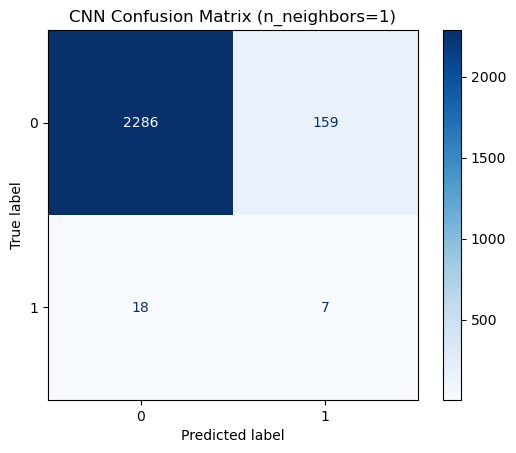


Test con n_neighbors = 3
Shape del dataset bilanciato: Counter({np.int64(0): 243, np.int64(1): 59})
Accuracy: 0.8688259109311741
F1-score (per classe): [0.92953458 0.05263158]


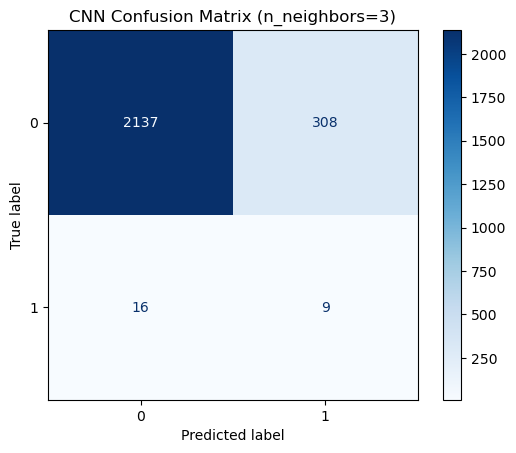

In [12]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


print("--- Valutazione parametri per CNN ---")
for n_neigh in [1, 3]:
    print(f"\nTest con n_neighbors = {n_neigh}")
    cnn = CondensedNearestNeighbour(random_state=42, n_neighbors=n_neigh, n_jobs=-1)
    X_res_cnn, y_res_cnn = cnn.fit_resample(X_trainp, y_trainp)
    print('Shape del dataset bilanciato:', Counter(y_res_cnn))
    
    # Fit del modello esistente
    clf.fit(X_res_cnn, y_res_cnn)
    y_pred_cnn = clf.predict(X_testp)
    
    print('Accuracy:', accuracy_score(y_testp, y_pred_cnn))
    print('F1-score (per classe):', f1_score(y_testp, y_pred_cnn, average=None))
    
    cm = confusion_matrix(y_testp, y_pred_cnn)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues')
    plt.title(f'CNN Confusion Matrix (n_neighbors={n_neigh})')
    plt.show()


Resampled dataset shape Counter({np.int64(0): 390, np.int64(1): 59})
Accuracy 0.9368421052631579
F1-score [0.9672956  0.08235294]
              precision    recall  f1-score   support

           0       0.99      0.94      0.97      2445
           1       0.05      0.28      0.08        25

    accuracy                           0.94      2470
   macro avg       0.52      0.61      0.52      2470
weighted avg       0.98      0.94      0.96      2470



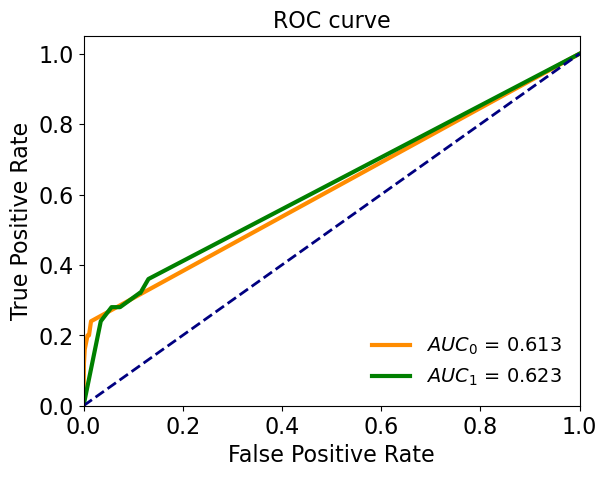

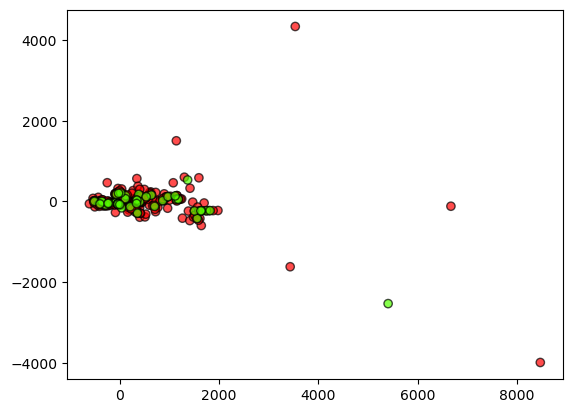

In [18]:
# --- CondensedNearestNeighbour ---

cnn = CondensedNearestNeighbour(random_state=42, n_jobs=10)
X_res, y_res = cnn.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res))

# fit
clf = DecisionTreeClassifier(min_samples_leaf=3, random_state=42)
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

### Scelta Parametri: ADASYN
**Logica della scelta:**
ADASYN genera campioni sintetici concentrandosi sulle regioni in cui la densità dei campioni di minoranza è più bassa rispetto a quelli di maggioranza (casi più difficili da imparare). Il parametro critico è `n_neighbors`, che stabilisce quanti vicini utilizzare per calcolare la densità e generare i nuovi campioni. 
Poiché abbiamo solo 25 campioni minoritari, un numero di vicini troppo alto rischierebbe di includere punti troppo lontani, generando campioni non rappresentativi. Testeremo `n_neighbors` in `[3, 5, 7]` per trovare il giusto compromesso tra varianza dei campioni generati e fedeltà alla distribuzione originaria.

--- Valutazione parametri per ADASYN ---

Test con n_neighbors = 3
F1-score (per classe): [0.99017199 0.14285714]


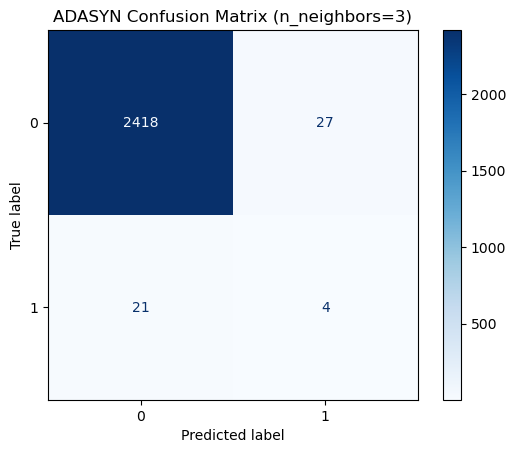


Test con n_neighbors = 5
F1-score (per classe): [0.9897541  0.16666667]


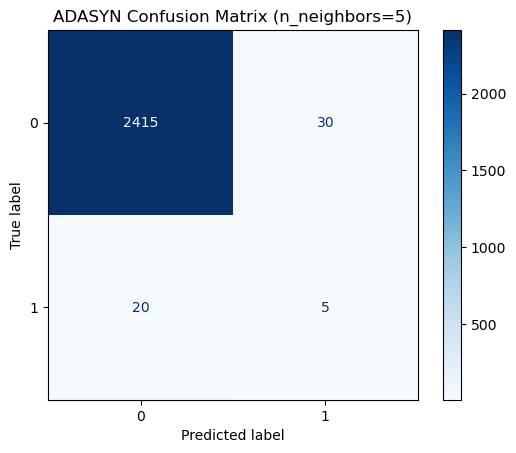


Test con n_neighbors = 7
F1-score (per classe): [0.98851518 0.125     ]


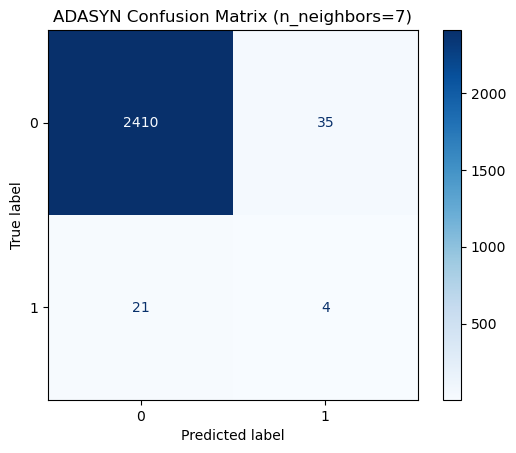

In [14]:
# --- Tuning ADASYN ---
from imblearn.over_sampling import ADASYN
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("--- Valutazione parametri per ADASYN ---")
for n_neigh in [3, 5, 7]:
    print(f"\nTest con n_neighbors = {n_neigh}")
    ada = ADASYN(random_state=42, n_neighbors=n_neigh)
    X_res_ada, y_res_ada = ada.fit_resample(X_trainp, y_trainp)
    
    # Fit del modello
    clf.fit(X_res_ada, y_res_ada)
    y_pred_ada = clf.predict(X_testp)
    
    print('F1-score (per classe):', f1_score(y_testp, y_pred_ada, average=None))
    
    cm = confusion_matrix(y_testp, y_pred_ada)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues')
    plt.title(f'ADASYN Confusion Matrix (n_neighbors={n_neigh})')
    plt.show()


Resampled dataset shape Counter({np.int64(1): 5715, np.int64(0): 5702})
Accuracy 0.979757085020243
F1-score [0.9897541  0.16666667]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2445
           1       0.14      0.20      0.17        25

    accuracy                           0.98      2470
   macro avg       0.57      0.59      0.58      2470
weighted avg       0.98      0.98      0.98      2470



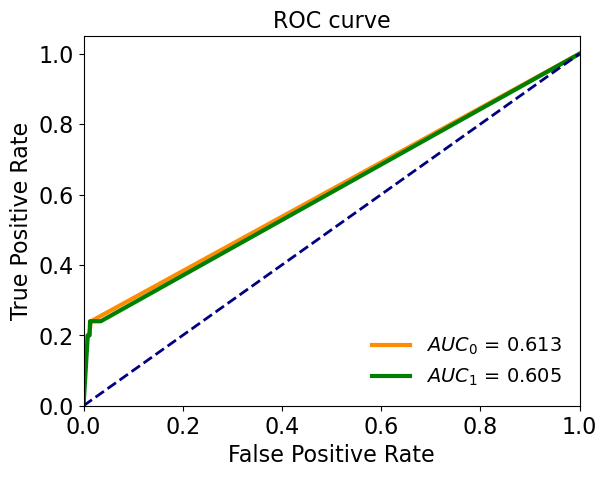

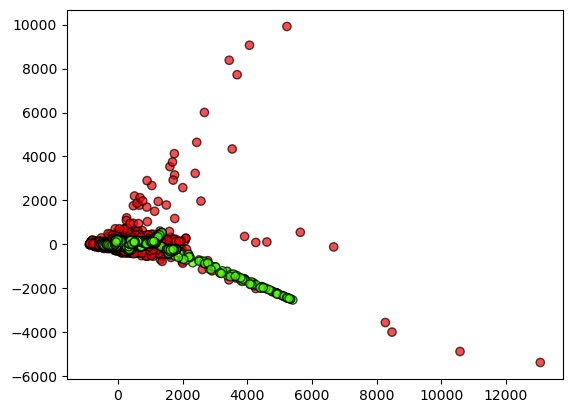

In [15]:
# --- ADASYN ---

ada = ADASYN(random_state=42)
X_res, y_res = ada.fit_resample(X_trainp, y_trainp)
#guidotti non mette i train ma X e y complete quindi boh controlla
print('Resampled dataset shape %s' % Counter(y_res))

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

### Scelta Parametri: SMOTE
**Logica della scelta:**
A differenza di ADASYN, SMOTE interpola linearmente in modo uniforme lungo tutti i campioni minoritari. Anche qui il parametro chiave è `k_neighbors`. L'effetto di k_neighbors regola l'estensione dello spazio coperto dai campioni sintetici. 
Valuteremo `k_neighbors` in `[3, 5, 7]`. In contesti di forte sbilanciamento e pochi campioni (25), un k basso (es. 3) crea campioni molto simili a quelli originali (minore rischio di overlapping con la classe maggioritaria), mentre un k più alto esplora un volume maggiore.

--- Valutazione parametri per SMOTE ---

Test con k_neighbors = 3
F1-score (per classe): [0.9895556  0.10526316]


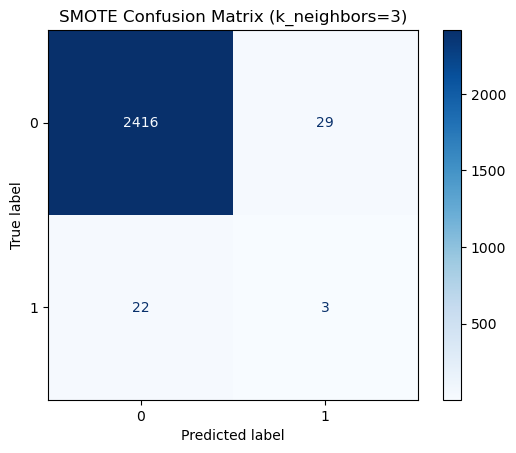


Test con k_neighbors = 5
F1-score (per classe): [0.9897541  0.16666667]


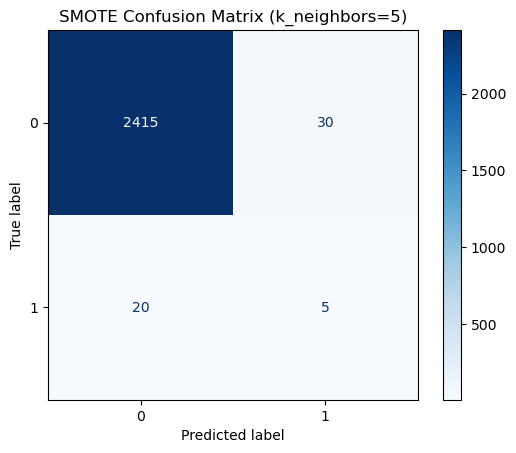


Test con k_neighbors = 7
F1-score (per classe): [0.98831249 0.0952381 ]


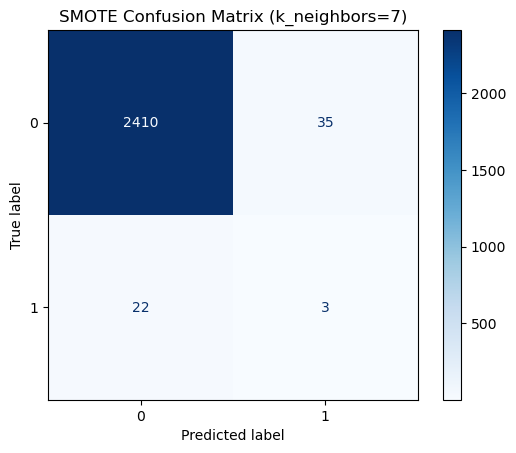

In [16]:
# --- Tuning SMOTE ---
print("--- Valutazione parametri per SMOTE ---")
for k_neigh in [3, 5, 7]:
    print(f"\nTest con k_neighbors = {k_neigh}")
    smote = SMOTE(random_state=42, k_neighbors=k_neigh)
    X_res_sm, y_res_sm = smote.fit_resample(X_trainp, y_trainp)
    
    # Fit del modello
    clf.fit(X_res_sm, y_res_sm)
    y_pred_sm = clf.predict(X_testp)
    
    print('F1-score (per classe):', f1_score(y_testp, y_pred_sm, average=None))
    
    cm = confusion_matrix(y_testp, y_pred_sm)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues')
    plt.title(f'SMOTE Confusion Matrix (k_neighbors={k_neigh})')
    plt.show()


Resampled dataset shape Counter({np.int64(0): 5702, np.int64(1): 5702})
Accuracy 0.979757085020243
F1-score [0.9897541  0.16666667]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2445
           1       0.14      0.20      0.17        25

    accuracy                           0.98      2470
   macro avg       0.57      0.59      0.58      2470
weighted avg       0.98      0.98      0.98      2470



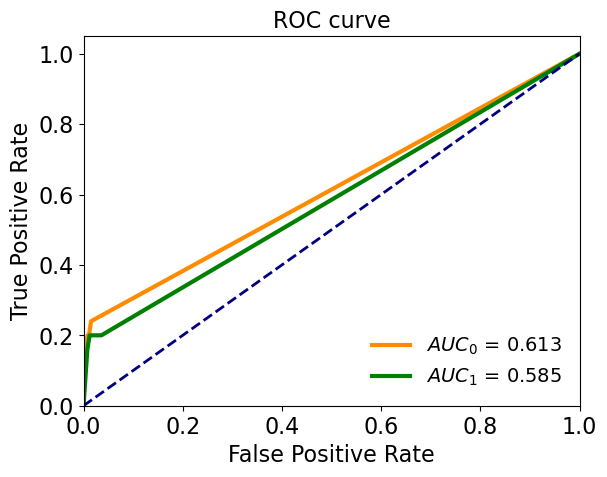

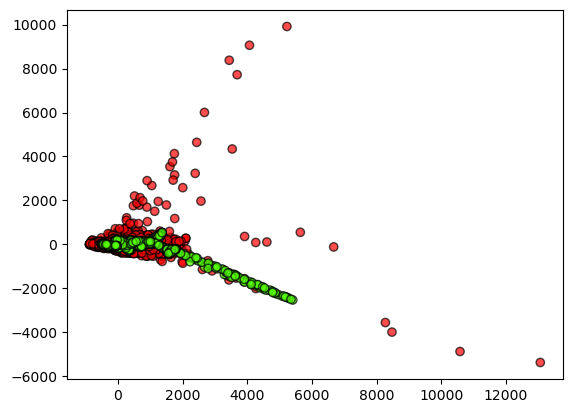

In [ ]:
# --- SMOTE ---

sm = SMOTE(random_state=42, k_)
X_res, y_res = sm.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res))

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

## Undersampling

### Tomek Links

Resampled dataset shape Counter({np.int64(0): 5688, np.int64(1): 59})
Accuracy 0.9878542510121457
F1-score [0.99388504 0.11764706]
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2445
           1       0.22      0.08      0.12        25

    accuracy                           0.99      2470
   macro avg       0.61      0.54      0.56      2470
weighted avg       0.98      0.99      0.99      2470



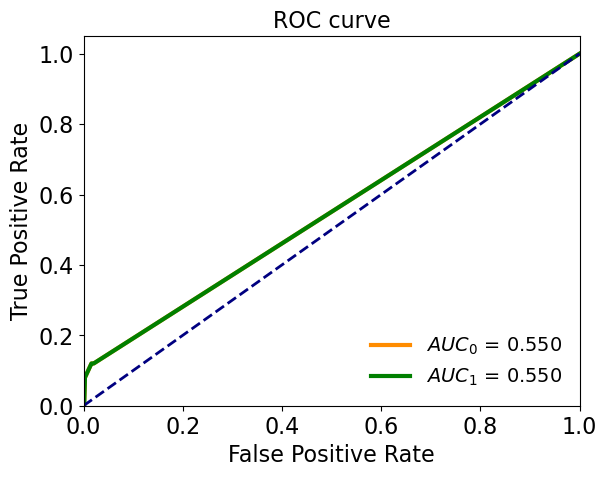

In [56]:
tl = TomekLinks()
X_res, y_res = tl.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res))

# fit 
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

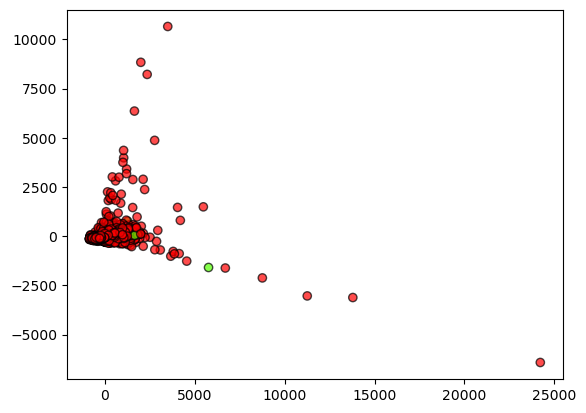

In [57]:
pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

Resampled dataset shape Counter({np.int64(0): 5698, np.int64(1): 59})
Accuracy 0.9870445344129555
F1-score [0.99347737 0.05882353]
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2445
           1       0.11      0.04      0.06        25

    accuracy                           0.99      2470
   macro avg       0.55      0.52      0.53      2470
weighted avg       0.98      0.99      0.98      2470



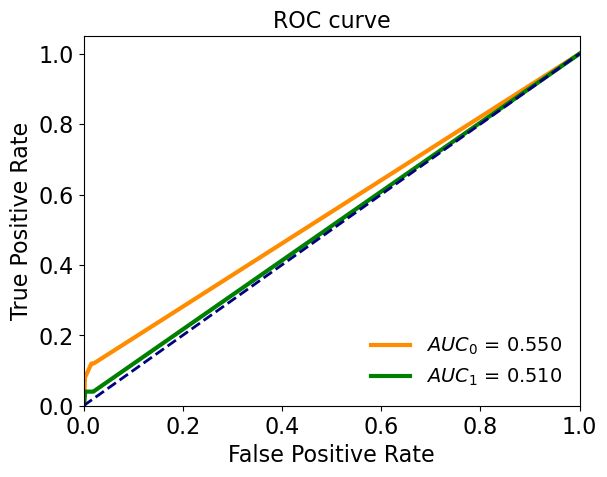

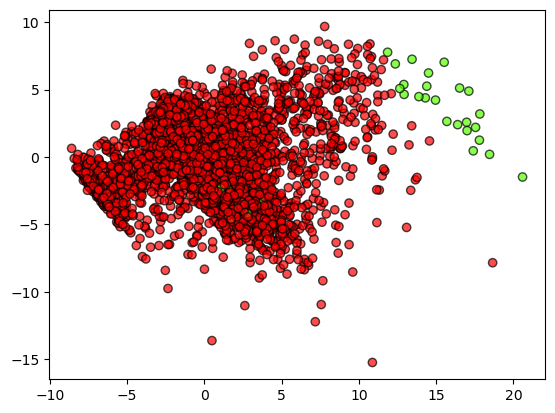

In [58]:
# tomek mi sa che si standardizza però
tl = TomekLinks()
X_res, y_res = tl.fit_resample(X_trainp_s, y_trainp_s)
print('Resampled dataset shape %s' % Counter(y_res))

# fit 
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp_s)
print('Accuracy %s' % accuracy_score(y_testp_s, y_pred))
print('F1-score %s' % f1_score(y_testp_s, y_pred, average=None))
print(classification_report(y_testp_s, y_pred))

# roc
y_score = clf.predict_proba(X_testp_s)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp_s, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

pca = PCA(n_components=2)
pca.fit(X_trainp_s)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

### CondensedNearestNeighbour

Resampled dataset shape Counter({np.int64(0): 393, np.int64(1): 59})
Accuracy 0.9550607287449393
F1-score [0.97693746 0.12598425]
              precision    recall  f1-score   support

           0       0.99      0.96      0.98      2445
           1       0.08      0.32      0.13        25

    accuracy                           0.96      2470
   macro avg       0.54      0.64      0.55      2470
weighted avg       0.98      0.96      0.97      2470



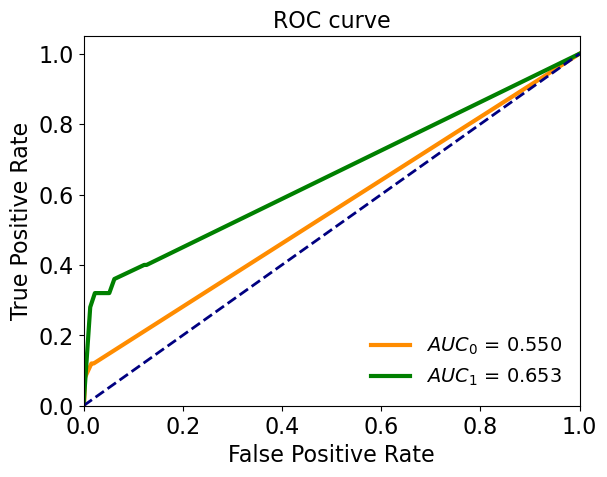

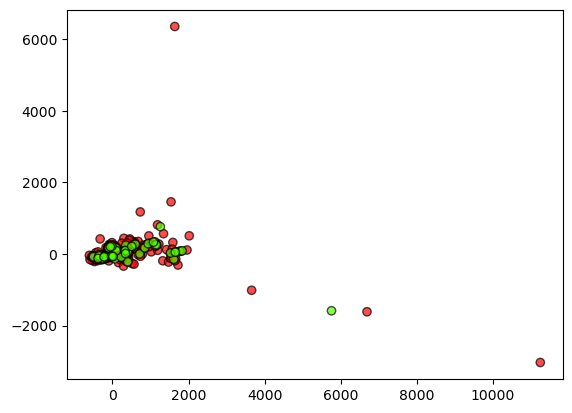

In [59]:
cnn = CondensedNearestNeighbour(random_state=42, n_jobs=10)
X_res, y_res = cnn.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res))

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

### ClusterCentroids

In [60]:
from sklearn.cluster import MiniBatchKMeans
from imblearn.under_sampling import ClusterCentroids

Resampled dataset shape Counter({np.int64(0): 59, np.int64(1): 59})
Accuracy 0.08016194331983806
F1-score [0.13282443 0.02068966]
              precision    recall  f1-score   support

           0       0.99      0.07      0.13      2445
           1       0.01      0.96      0.02        25

    accuracy                           0.08      2470
   macro avg       0.50      0.52      0.08      2470
weighted avg       0.98      0.08      0.13      2470



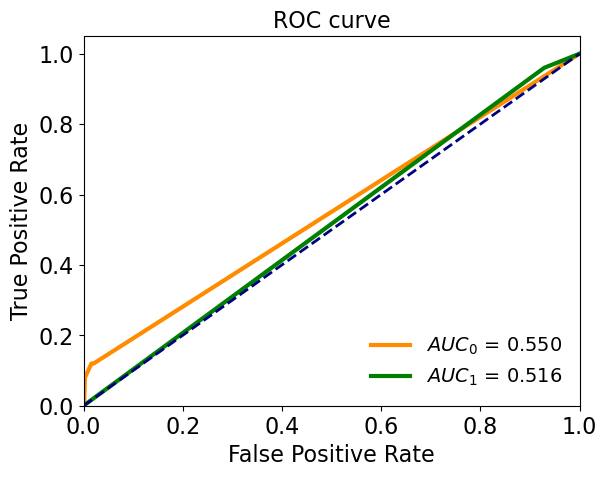

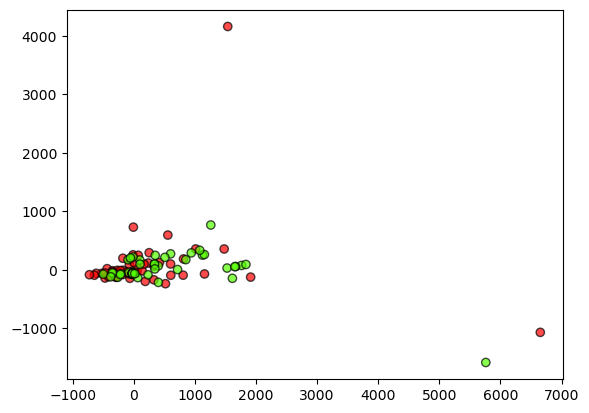

In [61]:
cc = ClusterCentroids(
    estimator=MiniBatchKMeans(n_init=1, random_state=0), random_state=42
)
X_res, y_res = cc.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res))

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

## Oversampling

### SMOTE

Resampled dataset shape Counter({np.int64(0): 5702, np.int64(1): 5702})
Accuracy 0.9748987854251012
F1-score [0.98727944 0.06060606]
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      2445
           1       0.05      0.08      0.06        25

    accuracy                           0.97      2470
   macro avg       0.52      0.53      0.52      2470
weighted avg       0.98      0.97      0.98      2470



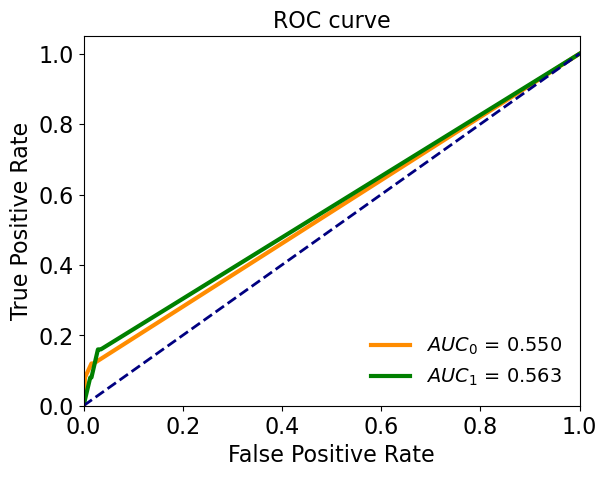

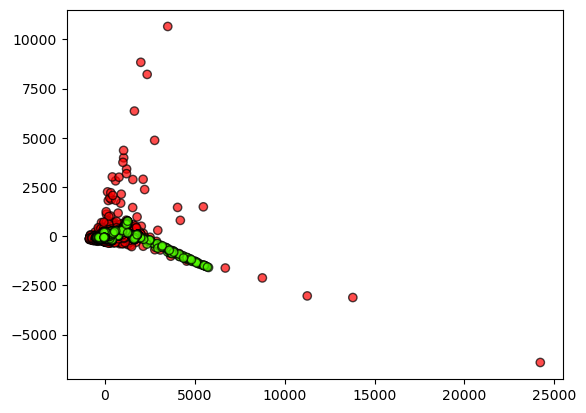

In [62]:
sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res))

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

### ADASYN

Resampled dataset shape Counter({np.int64(1): 5719, np.int64(0): 5702})
Accuracy 0.9817813765182186
F1-score [0.99080319 0.04255319]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2445
           1       0.05      0.04      0.04        25

    accuracy                           0.98      2470
   macro avg       0.52      0.52      0.52      2470
weighted avg       0.98      0.98      0.98      2470



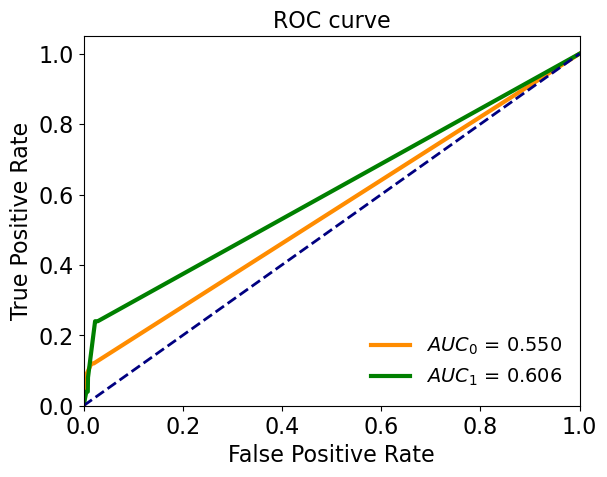

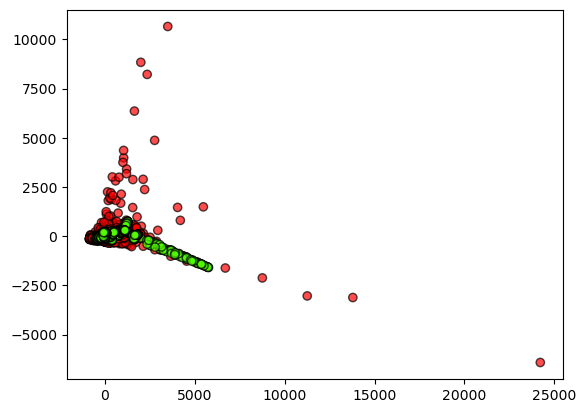

In [63]:
ada = ADASYN(random_state=42)
X_res, y_res = ada.fit_resample(X_trainp, y_trainp)
#guidotti non mette i train ma X e y complete quindi boh controlla
print('Resampled dataset shape %s' % Counter(y_res))

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

## Balancing at the Algorithm Level

### Class Weight

Accuracy 0.9724696356275304
F1-score [0.98601399 0.12820513]
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      2445
           1       0.09      0.20      0.13        25

    accuracy                           0.97      2470
   macro avg       0.54      0.59      0.56      2470
weighted avg       0.98      0.97      0.98      2470



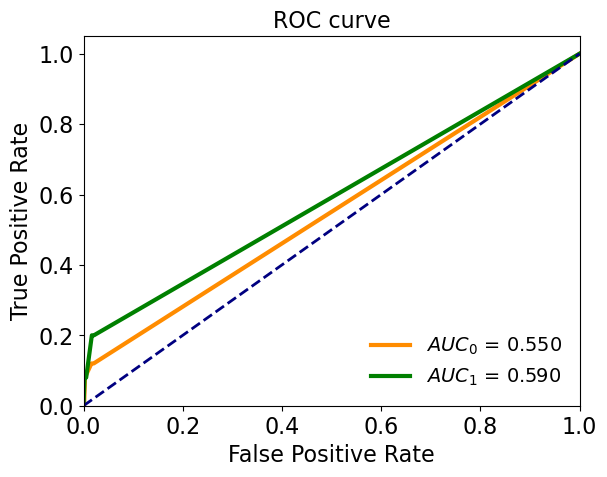

In [64]:
# fit
clf = DecisionTreeClassifier(min_samples_leaf=3, 
                             class_weight={0:1, 1: 5}, random_state=42)
clf.fit(X_trainp, y_trainp)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

### decision threshold

Accuracy 0.9870445344129555
F1-score [0.99347471 0.11111111]
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2445
           1       0.18      0.08      0.11        25

    accuracy                           0.99      2470
   macro avg       0.59      0.54      0.55      2470
weighted avg       0.98      0.99      0.98      2470



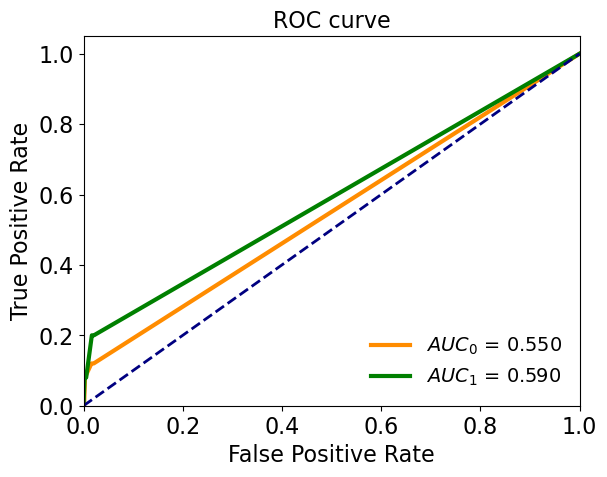

In [65]:
def adjusted_predict(X, thr=0.5):
    y_score = clf.predict_proba(X_testp)[:, 1]
    return np.array([1 if y > thr else 0 for y in y_score])

# fit
clf.fit(X_trainp, y_trainp)

# predict
y_pred = adjusted_predict(X_testp, thr=0.9)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

converrebbe fare df con tutti i risultati riassunti da mettere nel report 

usare cathc22 per timeseries

# Advanced Classification

possibili da usare per classificazione oltre a sii:
- BIA-BIA_Activity_Level_num


In [42]:
# dataset
df = pd.read_parquet("df_pulito.parquet")

# veloce escamotage per elencare tutte le variabili questionario
pciat_cols = [f"PCIAT-PCIAT_{i:02d}" for i in range(1, 21)]
X = df.drop(columns=["sii","risultati", "PCIAT-PCIAT_Total", "id"] + pciat_cols)
y = df["sii"]  # per valutare sii, praticamente classificazione

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=222)

#Train Test Ore
X_ore = df.drop(columns=["risultati", "id",
                "PreInt_EduHx-computerinternet_hoursday"])
y_ore = df['PreInt_EduHx-computerinternet_hoursday']

X_train_ore, X_test_ore, y_train_ore, y_test_ore = train_test_split(
    X_ore, y_ore, test_size=0.3, random_state=222)

#Train Test Attività Fisica
X_af = df.drop(columns=["risultati", "BIA-BIA_Activity_Level_num", "id"])
y_af = df['BIA-BIA_Activity_Level_num']

X_train_af, X_test_af, y_train_af, y_test_af = train_test_split(
    X_af, y_af, test_size=0.3, random_state=222)